# Training of airgun classifier

### Training data

we have a set of 150 files annotated of a total of 474. The files are annotated in raven with a single class. 

### Models to try

Altough the annotations are boxes i though of using start and finish to train a perch like model  that works in chunks and also a model based on the waveform.; The waveform model i never trained before. 

- YOLO detection model (ultralytics, opensoudnscape, hugginface)
-  ResnEt deteciton model (opensoudnscape, hugginface)
- Perch or Birdnet style model (opensoundscape)
- Wav2Vec2-BERT based on waveforms  (huggin face)

# Pre processing
The raven labels might need some work because raven lite does not create all the columns i need to create. 

Since most airguns are very lo frequency, i will like to do a band  pass on the data and annotations before hand. 


### Proposed workflow

Load the data -> band filter pass  -> divide the annotations between, start and finish or boxes -> split into train and test (100,150) -> train all models -> run on the rest of the data ->  active learning?

In [ ]:
### Object detection models based on spectograms

In [ ]:
from opensoundscape import Audio, Spectrogram
from opensoundscape.annotations import BoxedAnnotations

from pathlib import Path


# load the annotation file from Raven
annotation_file = Path(r"/mnt/c/Users/247404/Documents/2024/HABITWAL FINAL REPORT/Airgun_detector/annotations_airguns150.txt")
audio_file = Path(r"/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Catalog AMARs/Airgun/all_together.wav") 


Here i load an example audio, the bandpass cuts the frequencies outside my range

<Axes: xlabel='Time (s)', ylabel='Frequency (Hz)'>

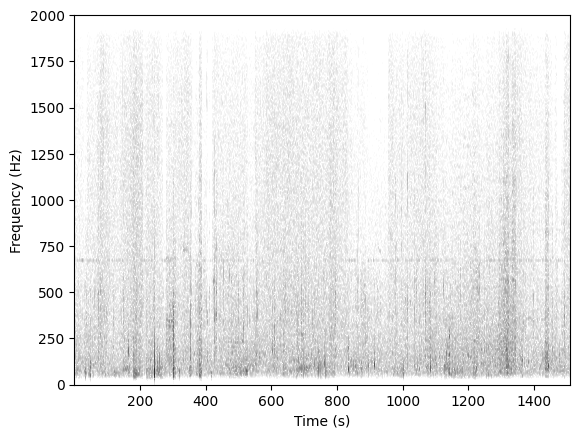

In [28]:
audio = Audio.from_file(audio_file).bandpass(low_f=50, high_f=2000, order=4).resample(4000)   
Spectrogram.from_audio(audio, fft_size=1024*4).plot()

Load raven file, however opensoundscape only takes singel annotation files per audiofile which is super strange to me. I will need to write a small snippet to divide my annotation file into subfiles

Update 16/10/2026: The snippet was too complicated because cornell sucks (to many things to track on the Lite table and to create by hand), so i just pasted all the files together with ffmpeg

In [2]:
annot_list = [annotation_file]
audio_list = [audio_file]

# Create an object from Raven file
annotations = BoxedAnnotations.from_raven_files(
    raven_files=annot_list,
    audio_files=audio_list,
    annotation_column=None,  # Put None if you don't have an annotation column
)

# Inspect the object's .df attribute
# which contains the table of annotations
annotations.df.head()
annotations.df["annotation"] = "airgun"

In [3]:

# Parameters to use for label creation
clip_duration = 5
clip_overlap = 0
min_label_overlap = 0.25

# Create dataframe of one-hot labels
clip_labels = annotations.clip_labels(
    clip_duration = clip_duration,
    clip_overlap = clip_overlap,
    min_label_overlap = min_label_overlap,
)

clips with airguns labels:



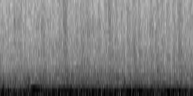
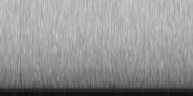
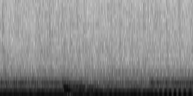
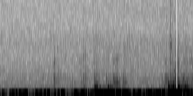

In [4]:
from opensoundscape.visualization import inspect

print(f"clips with airguns labels:")
widget = inspect(
    clip_labels, N=4, bandpass_range=(0, 3000)
)


Create test, train and validation script, 

In [5]:
labels = clip_labels.sort_index(level="start_time")
n = len(labels)
train_df = labels.iloc[: int(0.5 * n)]
val_df   = labels.iloc[int(0.5 * n) : int(0.85 * n)]
test_df  = labels.iloc[int(0.85 * n) :]

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(d), "clips,",d["airgun"].sum(), "with airgun")

train 151 clips, 81 with airgun
val 106 clips, 83 with airgun
test 46 clips, 37 with airgun


In [6]:
from opensoundscape.ml.cnn_architectures import list_architectures; list_architectures()

['resnet18',
 'resnet34',
 'resnet50',
 'resnet101',
 'resnet152',
 'alexnet',
 'vgg11_bn',
 'squeezenet1_0',
 'densenet121',
 'efficientnet_b0',
 'efficientnet_b1',
 'efficientnet_b4']

This is a list of the Models available in opensoundscape and descriptions (AI generated use with caution). 

| Model | Year | Parameters | Relative speed | Notes |
|---|---|---|---|---|
| resnet18 | 2015 | 11.7 M | Fast | The usual first choice. Good balance for small datasets. |
| resnet34 | 2015 | 21.8 M | Fast | A deeper resnet18 with a bit more capacity. The tutorial's default. |
| resnet50 | 2015 | 25.6 M | Medium | A common strong baseline, but it benefits from more data. |
| resnet101 | 2015 | 44.5 M | Slow | Very deep. Overkill for about 150 clips. |
| resnet152 | 2015 | 60.2 M | Slowest ResNet | Same as resnet101, only more so. |
| alexnet | 2012 | 61.1 M | Fast | Old and shallow. Most of its parameters are in the final layers. Mainly of historical interest. |
| vgg11_bn | 2014 | 132.9 M | Slow, memory-heavy | A simple design but very large, so it overfits small data easily. |
| squeezenet1_0 | 2016 | 1.2 M | Very fast | Tiny and good on a CPU, but usually less accurate. |
| densenet121 | 2017 | 8.0 M | Medium | Few parameters and often good on small data, but it uses more memory and runs slower than its size suggests. |
| efficientnet_b0 | 2019 | 5.3 M | Fast–medium | Very good accuracy for its size. |
| efficientnet_b1 | 2019 | 7.8 M | Medium | A slightly larger b0. |
| efficientnet_b4 | 2019 | 19.3 M | Slow | Designed for larger images (380 px), so you gain little at smaller sizes. |

Speeds are rough comparisons, not measurements. In OpenSoundscape, all of these start from pretrained ImageNet weights (`weights="DEFAULT"`).

In [22]:
# Create a CNN object designed to recognize 3-second samples
from opensoundscape import CNN

# Use resnet34 architecture
architecture = "efficientnet_b0"

# Can use this code to get your classes, if needed
class_list = list(train_df.columns)
class_list
model = CNN(
    architecture=architecture,
    classes=class_list,
    sample_duration=clip_duration,  # 10s, selected above
    sample_rate=6000,
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /home/biofelip/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:01<00:00, 11.7MB/s]


In [23]:
print(f"model.device is: {model.device}")


model.device is: cuda:0


In [24]:
import torch; print(torch.__version__, torch.cuda.is_available())

2.5.1+cu121 True


In [25]:
import wandb
from Keys import api_key

# try:
wandb.login()
wandb_session = wandb.init(
    entity="AI_for_Ecology_ITAW",  # replace with your entity/group name
    project="Airgun_detector",  # replace with your project name
    name="Efficientnetb0 airgun",
)
# except:  # if wandb.init fails, don't use wandb logging
#     print("failed to create wandb session. wandb session will be None")
#     wandb_session = None

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


loss,▇▇▅▂█▅▃▄▃▂▆▇▄▆▆▇▃▃▃▄▅▃▄▂▃▃▄▂▃▂▁▄▃▂▅▃▃▂▃▂
step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇███
loss,0.35812
step,198


In [21]:
checkpoint_folder = Path("Efficient_net")

# Note: if you don't want to compute and log metrics for each individual class, set
# model.compute_per_class_metrics = False

Model training

In [26]:
# %%capture --no-stdout --no-display
# Uncomment the line above to silence outputs from this cell

model.train(
    train_df,
    val_df,
    steps=300,
    batch_size=16,
    log_interval=2,  # log progress every 100 batches
    validation_interval=2,
    # num_workers=num_workers,  # parallelized cpu tasks for preprocessing
    wandb_session=wandb_session,
    save_path=checkpoint_folder,  # location to save checkpoints
)

  0%|          | 0/300 [00:00<?, ?it/s]

Step: 0/300 (0.0%)
	Running Average Loss: 0.656
	Most Recent Step Loss: 0.656

Validation.


  0%|          | 0/7 [00:00<?, ?it/s]

Step: 2/300 (0.7%)
	Running Average Loss: 0.709
	Most Recent Step Loss: 0.718

Validation.


  0%|          | 0/7 [00:00<?, ?it/s]

...

Step: 296/300 (98.7%)
	Running Average Loss: 0.255
	Most Recent Step Loss: 0.228

Validation.


  0%|          | 0/7 [00:00<?, ?it/s]

Step: 298/300 (99.3%)
	Running Average Loss: 0.347
	Most Recent Step Loss: 0.242

Validation.


  0%|          | 0/7 [00:00<?, ?it/s]


Best Model Appears at Step 212 with Validation score 0.959.
